# U-Net : Convolutional Networks for Biomedical Image Segmentation
**Ronneberger, Fischer, Brox (2015) — arXiv:1505.04597** · Implémentation **NumPy from scratch (sans PyTorch)**, cellule par cellule, avec toutes les sorties exécutées.

### Plan
1. Ce que dit le papier (résumé des idées clés)
2. Architecture (Fig. 1) : tailles des feature maps, nombre de couches, nombre de paramètres
3. Briques de base en NumPy : convolution *valid*, ReLU, max-pooling, up-convolution 2×2, initialisation He
4. Le réseau U-Net complet (forward + backward) et **vérification des gradients**
5. Fonction de coût : softmax pixel à pixel + entropie croisée **pondérée** (Éq. 1)
6. Données : jeu type ISBI 2012 (EM), carte de poids (Éq. 2, Fig. 3)
7. Stratégie *overlap-tile* (Fig. 2) et augmentation par **déformations élastiques** (§3.1)
8. Entraînement (SGD, momentum 0,99, batch = 1 image)
9. Inférence par tuiles, évaluation (pixel error, Rand error, IoU) et visualisation
10. Bilan : correspondance papier ↔ notebook et passage à l'échelle



## 1. Ce que dit le papier

**Problème.** En imagerie biomédicale on veut une *classe par pixel* (segmentation), mais on dispose de très peu d'images annotées (quelques dizaines).

**Point de départ : Ciresan et al. [1].** Réseau en fenêtre glissante : un patch autour de chaque pixel prédit sa classe. Deux défauts : (i) lent et redondant (patches qui se chevauchent), (ii) compromis entre **localisation** (petits patches) et **contexte** (grands patches, plus de pooling).

**Idées de U-Net** (construit sur le « fully convolutional network » [9]) :

| Idée | Où dans le papier | Effet |
|---|---|---|
| Chemin contractant + chemin expansif **symétriques** (forme en U) | §2, Fig. 1 | contexte + localisation précise |
| Beaucoup de canaux dans le chemin expansif, **concaténation** (copy & crop) avec les features haute résolution | §1–2 | propage le contexte vers les hautes résolutions |
| Convolutions **valid** (non paddées) + stratégie **overlap-tile** avec extrapolation par miroir | §1, Fig. 2 | segmentation « sans couture » d'images arbitrairement grandes |
| **Déformations élastiques** (grille 3×3, σ = 10 px, interpolation bicubique) | §3.1 | invariance apprise avec très peu d'images |
| **Perte pondérée** : poids fort sur les fines frontières entre cellules qui se touchent | §3, Éq. 1–2, Fig. 3 | sépare les objets collés |
| Init. **He** (écart-type √(2/N)) | §3 | variance ≈ 1 dans toutes les feature maps |
| SGD, **momentum 0,99**, batch = 1 grande tuile | §3 | tuiles larges plutôt que gros batch |

**Résultats annoncés** : meilleur *warping error* (0,000353) sur le challenge EM ISBI 2012 (Tableau 1) ; IoU 92 % (PhC-U373) et 77,5 % (DIC-HeLa) au challenge de suivi cellulaire 2015 (Tableau 2) ; entraînement ≈ 10 h sur un Titan 6 Go ; segmentation 512×512 en < 1 s.

*Remarque sur l'Éq. 1* : le papier écrit E = Σ w(x)·log(p_ℓ(x)(x)) ; pour obtenir une énergie **à minimiser**, il faut le signe moins (entropie croisée) : E = −Σ w(x)·log p_ℓ(x)(x). C'est ce que le code utilise.

In [1]:
import numpy as np, time, warnings
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "image.cmap": "gray"})
SEED = 0
rng = np.random.default_rng(SEED)
print("NumPy", np.__version__)

NumPy 2.0.2


## 2. Architecture (Fig. 1)

Chemin contractant : *2 × (conv 3×3 non paddée + ReLU)* puis *max-pool 2×2 stride 2*, en **doublant** les canaux à chaque étape.
Chemin expansif : *up-conv 2×2* (canaux ÷ 2), **concaténation** avec la feature map correspondante du chemin contractant **rognée** (les convolutions non paddées font perdre 2 pixels par couche), puis *2 × (conv 3×3 + ReLU)*.
Dernière couche : **conv 1×1** vers le nombre de classes. Au total **23 couches convolutives**.

La fonction ci-dessous ne calcule rien : elle suit seulement les **tailles** et rejette les tuiles invalides (le papier exige que chaque max-pooling s'applique à une taille *paire*).

In [2]:
def unet_shapes(s, depth=4, k=3):
    """Trace arithmétique des tailles. Retourne None si la tuile est invalide."""
    skips, trace = [], [("entrée", s)]
    for l in range(depth):
        s -= 2 * (k - 1)
        if s <= 0 or s % 2: return None
        skips.append(s); trace.append((f"enc{l+1} (2 conv)", s))
        s //= 2; trace.append((f"pool{l+1}", s))
    s -= 2 * (k - 1)
    if s <= 0: return None
    trace.append(("bottleneck (2 conv)", s))
    for l in reversed(range(depth)):
        s *= 2; trace.append((f"up{l+1}", s))
        if skips[l] < s: return None
        s -= 2 * (k - 1)
        if s <= 0: return None
        trace.append((f"dec{l+1} (2 conv)", s))
    return trace

def count_params(base=64, depth=4, in_ch=1, n_classes=2):
    n = 0; cin = in_ch
    for l in range(depth):
        ch = base * 2**l; n += 9*cin*ch + ch + 9*ch*ch + ch; cin = ch
    ch = base * 2**depth; n += 9*cin*ch + ch + 9*ch*ch + ch
    for l in reversed(range(depth)):
        ch = base * 2**l
        n += 4*(2*ch)*ch + ch               # up-conv 2x2 : 2ch -> ch
        n += 9*(2*ch)*ch + ch + 9*ch*ch + ch  # 2 conv 3x3 après concat
    n += base*n_classes + n_classes         # conv 1x1
    return n

In [3]:
trace = unet_shapes(572, depth=4)
print(f"{'étape':<22}{'taille x-y':>10}")
for name, s in trace:
    print(f"{name:<22}{s:>6} x {s}")
print()
print("Tuile d'entrée du papier : 572 x 572  ->  sortie :", trace[-1][1], "x", trace[-1][1], "(Fig. 1 : 388 x 388) ✔")

n_conv3 = 2 * 4 + 2 + 2 * 4          # 8 (enc) + 2 (bottleneck) + 8 (dec)
n_up, n_1x1 = 4, 1
print("Convolutions 3x3 :", n_conv3, "| conv 1x1 :", n_1x1, "-> couches convolutives (3x3 + 1x1 + up-conv 2x2) =", n_conv3 + n_1x1 + n_up,
      "| sans les up-conv :", n_conv3 + n_1x1, "(le papier annonce 23 : 18 conv 3x3 + 4 up-conv + 1 conv 1x1)")
print("Paramètres du U-Net du papier (64 canaux de base, 1 canal d'entrée, 2 classes) :", f"{count_params(64, 4, 1, 2):,}")

étape                 taille x-y
entrée                   572 x 572
enc1 (2 conv)            568 x 568
pool1                    284 x 284
enc2 (2 conv)            280 x 280
pool2                    140 x 140
enc3 (2 conv)            136 x 136
pool3                     68 x 68
enc4 (2 conv)             64 x 64
pool4                     32 x 32
bottleneck (2 conv)       28 x 28
up4                       56 x 56
dec4 (2 conv)             52 x 52
up3                      104 x 104
dec3 (2 conv)            100 x 100
up2                      200 x 200
dec2 (2 conv)            196 x 196
up1                      392 x 392
dec1 (2 conv)            388 x 388

Tuile d'entrée du papier : 572 x 572  ->  sortie : 388 x 388 (Fig. 1 : 388 x 388) ✔
Convolutions 3x3 : 18 | conv 1x1 : 1 -> couches convolutives (3x3 + 1x1 + up-conv 2x2) = 23 | sans les up-conv : 19 (le papier annonce 23 : 18 conv 3x3 + 4 up-conv + 1 conv 1x1)
Paramètres du U-Net du papier (64 canaux de base, 1 canal d'entrée, 2 classes) :

**Quelles tailles de tuile sont valides ?** Pour 4 max-poolings, seules certaines tailles d'entrée donnent des tailles paires partout. On en liste quelques-unes ; 572 est l'une d'elles, et notre tuile réduite **284 → 100** en est une autre.

In [4]:
valid = [(s, unet_shapes(s, 4)[-1][1]) for s in range(150, 620) if unet_shapes(s, 4)]
print("Quelques couples (entrée -> sortie) valides pour 4 niveaux :")
print(valid[:6], "...", valid[-3:])
print("572 valide ?", unet_shapes(572, 4) is not None, "| 284 -> ", unet_shapes(284, 4)[-1][1], "| 571 valide ?", unet_shapes(571, 4) is not None)

Quelques couples (entrée -> sortie) valides pour 4 niveaux :
[(188, 4), (204, 20), (220, 36), (236, 52), (252, 68), (268, 84)] ... [(572, 388), (588, 404), (604, 420)]
572 valide ? True | 284 ->  100 | 571 valide ? False


## 3. Briques de base en NumPy

* **`Conv`** : convolution *valid* (k = 3, ou k = 1 pour la dernière couche), implémentée par *im2col* (`sliding_window_view` + un produit matriciel). Initialisation **He** : `std = sqrt(2/N)` avec `N = k·k·C_in` (§3 du papier).
* **`ReLU`**, **`MaxPool2`** (2×2, stride 2 ; le gradient est renvoyé à la position du maximum).
* **`UpConv2`** : convolution transposée 2×2 stride 2, qui double la résolution et réduit les canaux (28² → 56² dans la Fig. 1).

Chaque brique a `forward` et `backward` écrits à la main.

In [5]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

class Conv:
    def __init__(self, cin, cout, k, rng, dtype=np.float32):
        std = np.sqrt(2.0 / (cin * k * k))
        self.W = (rng.standard_normal((cout, cin, k, k)) * std).astype(dtype)
        self.b = np.zeros(cout, dtype=dtype)
        self.k = k
    def forward(self, x):
        self.x_shape = x.shape
        N, C, H, W = x.shape; k = self.k
        Ho, Wo = H - k + 1, W - k + 1
        if k == 1:
            cols = x.transpose(0, 2, 3, 1).reshape(-1, C)
        else:
            win = sliding_window_view(x, (k, k), axis=(2, 3))
            cols = win.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C * k * k)
        self.cols = cols
        out = cols @ self.W.reshape(self.W.shape[0], -1).T + self.b
        return np.ascontiguousarray(out.reshape(N, Ho, Wo, -1).transpose(0, 3, 1, 2))
    def backward(self, dout):
        N, F, Ho, Wo = dout.shape
        C = self.x_shape[1]; k = self.k
        dflat = dout.transpose(0, 2, 3, 1).reshape(-1, F)
        self.dW = (dflat.T @ self.cols).reshape(self.W.shape)
        self.db = dflat.sum(0)
        dcols = (dflat @ self.W.reshape(F, -1)).reshape(N, Ho, Wo, C, k, k)
        dx = np.zeros(self.x_shape, dtype=dout.dtype)
        for i in range(k):
            for j in range(k):
                dx[:, :, i:i+Ho, j:j+Wo] += dcols[:, :, :, :, i, j].transpose(0, 3, 1, 2)
        return dx

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, d):
        return d * self.mask

class MaxPool2:
    def forward(self, x):
        N, C, H, W = x.shape
        assert H % 2 == 0 and W % 2 == 0
        xr = x.reshape(N, C, H//2, 2, W//2, 2)
        out = xr.max(axis=(3, 5))
        self.mask = (xr == out[:, :, :, None, :, None])
        self.mask = self.mask / self.mask.sum(axis=(3, 5), keepdims=True)
        self.shape = x.shape
        return out
    def backward(self, d):
        return (self.mask * d[:, :, :, None, :, None]).reshape(self.shape)

class UpConv2:
    def __init__(self, cin, cout, rng, dtype=np.float32):
        std = np.sqrt(2.0 / (cin * 4))
        self.W = (rng.standard_normal((cin, cout, 2, 2)) * std).astype(dtype)
        self.b = np.zeros(cout, dtype=dtype)
    def forward(self, x):
        self.x = x
        N, C, H, W = x.shape
        out = np.einsum('nchw,coab->nohawb', x, self.W, optimize=True)
        out = out.reshape(N, -1, 2*H, 2*W) + self.b[None, :, None, None]
        return out
    def backward(self, d):
        N, O, H2, W2 = d.shape
        dr = d.reshape(N, O, H2//2, 2, W2//2, 2)
        self.dW = np.einsum('nchw,nohawb->coab', self.x, dr, optimize=True)
        self.db = d.sum(axis=(0, 2, 3))
        return np.einsum('nohawb,coab->nchw', dr, self.W, optimize=True)

In [6]:
# Exemple du papier : conv 3x3 avec 64 canaux en entrée -> N = 9*64 = 576
c = Conv(64, 64, 3, np.random.default_rng(1), np.float64)
print("N =", 9 * 64, "| std théorique sqrt(2/N) =", round(np.sqrt(2 / 576), 5), "| std empirique des poids =", round(c.W.std(), 5))

# Variance des activations après conv+ReLU empilées (but de l'init. He : ~ conserver la variance)
x = np.random.default_rng(2).standard_normal((1, 64, 40, 40))
r = np.random.default_rng(3)
for i in range(6):
    conv = Conv(64, 64, 3, r, np.float64); x = ReLU().forward(conv.forward(x))
    print(f"après {i+1} blocs conv+ReLU : E[x²] = {np.mean(x**2):.3f}")

N = 576 | std théorique sqrt(2/N) = 0.05893 | std empirique des poids = 0.05847
après 1 blocs conv+ReLU : E[x²] = 0.988
après 2 blocs conv+ReLU : E[x²] = 1.012
après 3 blocs conv+ReLU : E[x²] = 0.865
après 4 blocs conv+ReLU : E[x²] = 1.103
après 5 blocs conv+ReLU : E[x²] = 1.070
après 6 blocs conv+ReLU : E[x²] = 0.995


## 4. Le U-Net complet

La classe `UNet` assemble les briques (`depth` niveaux, `base` canaux) :

* **forward** : on mémorise la sortie de chaque bloc du chemin contractant (`skips`) ; après chaque up-conv on **rogne au centre** la skip-connection (`center_crop`) et on **concatène** sur l'axe des canaux ; un *dropout* (p = 0,5) est appliqué à la fin du chemin contractant (§3.1).
* **backward** : on rétropropage à la main, en renvoyant le gradient de la concaténation vers la skip (re-« paddée » par des zéros à l'endroit du rognage) **et** vers la branche expansive.

In [7]:
def center_crop(x, hw):
    h, w = hw
    oy, ox = (x.shape[2] - h) // 2, (x.shape[3] - w) // 2
    return x[:, :, oy:oy+h, ox:ox+w], (oy, ox)

class UNet:
    def __init__(self, in_ch=1, n_classes=2, base=4, depth=4, p_drop=0.5, seed=0, dtype=np.float32):
        rng = np.random.default_rng(seed)
        self.depth, self.p_drop, self.rng, self.dtype = depth, p_drop, rng, dtype
        self.enc, self.pool, self.up, self.dec = [], [], [], []
        cin = in_ch
        for l in range(depth):
            ch = base * 2**l
            self.enc.append([Conv(cin, ch, 3, rng, dtype), ReLU(), Conv(ch, ch, 3, rng, dtype), ReLU()])
            self.pool.append(MaxPool2()); cin = ch
        ch = base * 2**depth
        self.bott = [Conv(cin, ch, 3, rng, dtype), ReLU(), Conv(ch, ch, 3, rng, dtype), ReLU()]
        for l in range(depth):
            ch = base * 2**l
            self.up.append(UpConv2(2*ch, ch, rng, dtype))
            self.dec.append([Conv(2*ch, ch, 3, rng, dtype), ReLU(), Conv(ch, ch, 3, rng, dtype), ReLU()])
        self.final = Conv(base, n_classes, 1, rng, dtype)
    @staticmethod
    def _run(block, x):
        for layer in block: x = layer.forward(x)
        return x
    @staticmethod
    def _run_back(block, d):
        for layer in reversed(block): d = layer.backward(d)
        return d
    def layers_with_params(self):
        L = []
        for blk in self.enc + [self.bott] + self.dec:
            L += [l for l in blk if isinstance(l, Conv)]
        return L + self.up + [self.final]
    def n_params(self):
        return sum(l.W.size + l.b.size for l in self.layers_with_params())
    def forward(self, x, train=True):
        self.skips, self.crops, self.train = [], [], train
        for l in range(self.depth):
            x = self._run(self.enc[l], x)
            self.skips.append(x)
            x = self.pool[l].forward(x)
        x = self._run(self.bott, x)
        if train and self.p_drop > 0:           # dropout en fin de chemin contractant
            self.drop_mask = (self.rng.random(x.shape) > self.p_drop).astype(x.dtype) / (1 - self.p_drop)
            x = x * self.drop_mask
        for l in reversed(range(self.depth)):
            x = self.up[l].forward(x)
            skip, off = center_crop(self.skips[l], x.shape[2:])
            self.crops.append((l, skip.shape[1], off))
            x = np.concatenate([skip, x], axis=1)
            x = self._run(self.dec[l], x)
        return self.final.forward(x)
    def backward(self, dlogits):
        d = self.final.backward(dlogits)
        crops = {l: (cs, off) for (l, cs, off) in self.crops}
        dskips = [None] * self.depth
        for l in range(self.depth):             # ordre inverse du forward : niveau 0 d'abord
            d = self._run_back(self.dec[l], d)
            cs, (oy, ox) = crops[l]
            d_skip, d_up = d[:, :cs], d[:, cs:]
            sk = np.zeros_like(self.skips[l])
            h, w = d_skip.shape[2:]
            sk[:, :, oy:oy+h, ox:ox+w] = d_skip
            dskips[l] = sk
            d = self.up[l].backward(d_up)
        if self.train and self.p_drop > 0:
            d = d * self.drop_mask
        d = self._run_back(self.bott, d)
        for l in reversed(range(self.depth)):
            d = self.pool[l].backward(d) + dskips[l]
            d = self._run_back(self.enc[l], d)
        return d

In [8]:
BASE, DEPTH = 8, 4
net = UNet(in_ch=1, n_classes=2, base=BASE, depth=DEPTH, seed=SEED)
x = np.random.default_rng(0).standard_normal((1, 1, 284, 284)).astype(np.float32)
t0 = time.time(); z = net.forward(x, train=False); dt = time.time() - t0
print("entrée :", x.shape, "-> sortie :", z.shape, f"({dt:.2f}s)")
print("paramètres (réseau réduit) :", f"{net.n_params():,}", "| formule count_params :", f"{count_params(BASE, DEPTH, 1, 2):,}")
print("paramètres (réseau du papier, base=64) :", f"{count_params(64, 4, 1, 2):,}")

entrée : (1, 1, 284, 284) -> sortie : (1, 2, 100, 100) (0.44s)
paramètres (réseau réduit) : 485,682 | formule count_params : 485,682
paramètres (réseau du papier, base=64) : 31,030,658


## 5. Fonction de coût (Éq. 1)

Softmax pixel à pixel sur la dernière feature map : p_k(x) = exp(a_k(x)) / Σ_k' exp(a_k'(x)), puis entropie croisée **pondérée** :

E = − Σ_{x∈Ω} w(x) · log p_{ℓ(x)}(x)

où ℓ(x) est la vraie classe du pixel x et w(x) la carte de poids (§6). La fonction renvoie la perte (moyenne sur les pixels) **et** son gradient par rapport aux logits : pour un softmax + entropie croisée, ∂E/∂a_k = w · (p_k − 1[k = ℓ]).

In [9]:
def wce(logits, labels, w):
    z = logits - logits.max(1, keepdims=True)
    p = np.exp(z); p /= p.sum(1, keepdims=True)
    pl = np.take_along_axis(p, labels[:, None], 1)[:, 0]
    loss = -(w * np.log(pl + 1e-12)).sum() / w.size
    d = p.copy(); np.put_along_axis(d, labels[:, None], np.take_along_axis(d, labels[:, None], 1) - 1, 1)
    return loss, d * (w[:, None] / w.size)

### Vérification numérique des gradients

Avant d'entraîner, on vérifie `backward` contre des **différences finies centrées** sur un petit U-Net (profondeur 2, float64, sans dropout). Une erreur relative de l'ordre de 1e-6 à 1e-8 valide la rétropropagation, y compris celle de la concaténation avec rognage et de l'up-conv.

In [10]:
gc_net = UNet(1, 2, base=2, depth=2, p_drop=0, dtype=np.float64, seed=1)
s_in = next(s for s in range(30, 200) if unet_shapes(s, 2)); s_out = unet_shapes(s_in, 2)[-1][1]
g = np.random.default_rng(0)
xg = g.standard_normal((1, 1, s_in, s_in)); yg = g.integers(0, 2, (1, s_out, s_out)); wg = g.random((1, s_out, s_out)) + 0.5

def loss_only():
    return wce(gc_net.forward(xg, train=True), yg, wg)[0]

L, dz = wce(gc_net.forward(xg, train=True), yg, wg)
gc_net.backward(dz)
worst = 0.0
for layer in gc_net.layers_with_params():
    for _ in range(4):
        idx = tuple(g.integers(0, n) for n in layer.W.shape)
        old, eps = layer.W[idx], 1e-6
        layer.W[idx] = old + eps; Lp = loss_only()
        layer.W[idx] = old - eps; Lm = loss_only()
        layer.W[idx] = old
        num, ana = (Lp - Lm) / (2 * eps), layer.dW[idx]
        worst = max(worst, abs(num - ana) / max(1e-12, abs(num) + abs(ana)))
print(f"tuile {s_in}x{s_in} -> sortie {s_out}x{s_out}")
print(f"erreur relative maximale (poids de {len(gc_net.layers_with_params())} couches) : {worst:.2e}")
assert worst < 1e-4, "gradient incorrect"
print("✔ gradients corrects")

tuile 44x44 -> sortie 4x4
erreur relative maximale (poids de 13 couches) : 2.77e-06
✔ gradients corrects


## 6. Données

**Format du jeu ISBI 2012 décrit au §4 du papier** : 30 images 512×512 de coupes sériées en microscopie électronique ; chaque image a une segmentation vérité terrain : cellules (blanc) / membranes (noir).

Ici, par défaut, on génère un jeu **de même format** : cellules délimitées par de fines membranes sombres aux contours ondulés, avec textures, organites sombres, flou et bruit. Les images font **256×256** (pas 512) pour garder des temps de calcul raisonnables en NumPy. On crée **30 images d'entraînement** (comme dans le papier) et **5 images de test non vues**.

In [11]:
def make_em_like(size=256, n_cells=70, seed=0):
    rng = np.random.default_rng(seed)
    seeds = rng.uniform(0, size, (n_cells, 2))
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float64)
    wy = ndi.gaussian_filter(rng.standard_normal((size, size)), 18) 
    wx = ndi.gaussian_filter(rng.standard_normal((size, size)), 18)
    amp = 9.0 / (wy.std() + 1e-9)
    pts = np.stack([(yy + amp*wy).ravel(), (xx + amp*wx).ravel()], 1)
    d, idx = cKDTree(seeds).query(pts, k=2)
    membrane = ((d[:, 1] - d[:, 0]) < 2.2).reshape(size, size)
    cell_id = idx[:, 0].reshape(size, size)
    mask = ~membrane
    lum = 0.62 + 0.14 * rng.standard_normal(n_cells)
    img = lum[cell_id].astype(np.float64)
    img += 0.25 * ndi.gaussian_filter(rng.standard_normal((size, size)), 2.0) / 0.1 * 0.1
    blobs = np.zeros((size, size))
    for _ in range(size // 6):
        cy, cx = rng.integers(0, size, 2)
        blobs[cy, cx] = 1
    blobs = ndi.gaussian_filter(blobs, rng.uniform(2.5, 4.0)) * 60
    img -= 0.35 * np.clip(blobs, 0, 1) * mask
    img[membrane] = 0.12
    img = ndi.gaussian_filter(img, 0.8) + 0.05 * rng.standard_normal((size, size))
    return np.clip(img, 0, 1).astype(np.float32), mask.astype(np.uint8)

In [12]:
def instances_from_mask(mask):
    lab, n = ndi.label(mask)          # connectivité 4
    return lab, n

Jeu synthétique type EM : 30 images d'entraînement, 5 images de test (non vues)
taille d'une image : (256, 256) | fraction de pixels 'cellule' : 0.801


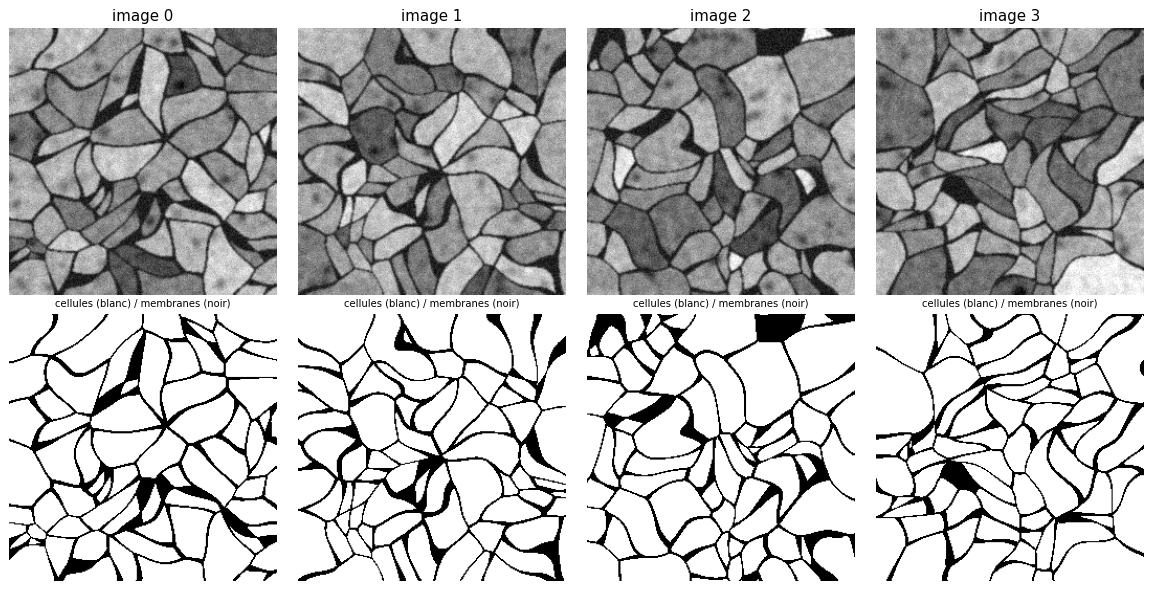

In [13]:
USE_REAL_ISBI = False       # mettre True si train-volume.tif / train-labels.tif sont à côté du notebook
import os

def load_real_isbi(img_path="train-volume.tif", lbl_path="train-labels.tif"):
    from PIL import Image, ImageSequence
    imgs = [np.asarray(f, dtype=np.float32) / 255.0 for f in ImageSequence.Iterator(Image.open(img_path))]
    msks = [(np.asarray(f) > 127).astype(np.uint8) for f in ImageSequence.Iterator(Image.open(lbl_path))]
    return imgs, msks

if USE_REAL_ISBI and os.path.exists("train-volume.tif"):
    all_imgs, all_msks = load_real_isbi()
    train_imgs, train_msks = all_imgs[:25], all_msks[:25]
    test_imgs,  test_msks  = all_imgs[25:], all_msks[25:]
    print("Jeu ISBI 2012 réel chargé :", len(train_imgs), "images d'entraînement,", len(test_imgs), "de validation")
else:
    pairs_tr = [make_em_like(256, 70, seed=s) for s in range(30)]
    pairs_te = [make_em_like(256, 70, seed=100 + s) for s in range(5)]
    train_imgs, train_msks = [p[0] for p in pairs_tr], [p[1] for p in pairs_tr]
    test_imgs,  test_msks  = [p[0] for p in pairs_te], [p[1] for p in pairs_te]
    print("Jeu synthétique type EM :", len(train_imgs), "images d'entraînement,", len(test_imgs), "images de test (non vues)")

print("taille d'une image :", train_imgs[0].shape, "| fraction de pixels 'cellule' :", round(float(np.mean([m.mean() for m in train_msks])), 3))

fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for j in range(4):
    ax[0, j].imshow(train_imgs[j], vmin=0, vmax=1); ax[0, j].set_title(f"image {j}"); ax[0, j].axis("off")
    ax[1, j].imshow(train_msks[j], vmin=0, vmax=1);  ax[1, j].set_title("cellules (blanc) / membranes (noir)", fontsize=8); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

### Carte de poids (Éq. 2, Fig. 3)

Pour forcer le réseau à apprendre les **fines séparations** entre cellules qui se touchent, chaque pixel reçoit un poids

w(x) = w_c(x) + w₀ · exp( −(d₁(x) + d₂(x))² / (2σ²) ),  avec w₀ = 10, σ ≈ 5 px

* w_c : équilibre les **fréquences de classes** (les membranes sont rares) ;
* d₁, d₂ : distances à la cellule la plus proche et à la deuxième plus proche. Quand d₁ + d₂ est petit, le pixel est coincé entre deux cellules → poids fort.

On obtient les **instances** (cellules) par composantes connexes du masque « cellule », puis d₁ et d₂ par transformées de distance euclidienne (calculées dans une boîte englobante élargie de 16 px par cellule, ce qui suffit car exp(−(16)²/50) ≈ 0,006).

In [14]:
def weight_map(mask, lab, n, w0=10.0, sigma=5.0, wc=None, margin=16):
    H, W = mask.shape
    BIG = 1e3
    d1 = np.full((H, W), BIG, np.float32); d2 = np.full((H, W), BIG, np.float32)
    for i, sl in enumerate(ndi.find_objects(lab), start=1):
        if sl is None: continue
        y0, y1 = max(sl[0].start - margin, 0), min(sl[0].stop + margin, H)
        x0, x1 = max(sl[1].start - margin, 0), min(sl[1].stop + margin, W)
        dc = ndi.distance_transform_edt(lab[y0:y1, x0:x1] != i).astype(np.float32)
        c1, c2 = d1[y0:y1, x0:x1], d2[y0:y1, x0:x1]
        n1 = np.minimum(c1, dc); n2 = np.minimum(c2, np.maximum(c1, dc))
        d1[y0:y1, x0:x1], d2[y0:y1, x0:x1] = n1, n2
    w = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
    if wc is not None:
        w = w + np.where(mask == 1, wc[1], wc[0])  # w_c : équilibrage des fréquences de classes
    return w.astype(np.float32), d1, d2

fréquences  membrane/cellule : [0.199 0.801] -> w_c = [2.51 0.62]
cartes de poids calculées pour 30 images en 1.5s
instances par image (moyenne) : 71.4 | poids min/moy/max : 0.62 4.81 11.74


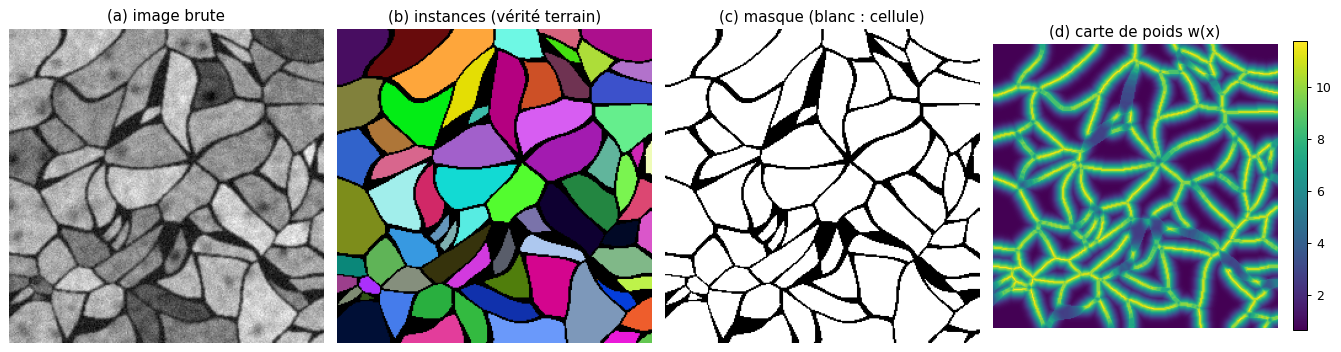

In [15]:
# w_c : poids inverses des fréquences de classes (0 = membrane, 1 = cellule), calculés sur tout l'entraînement
counts = np.array([sum(int((m == c).sum()) for m in train_msks) for c in (0, 1)])
wc = counts.sum() / (2.0 * counts)
print("fréquences  membrane/cellule :", np.round(counts / counts.sum(), 3), "-> w_c =", np.round(wc, 2))

t0 = time.time()
train_wts, train_lab = [], []
for m in train_msks:
    lab, n = instances_from_mask(m)
    w, d1, d2 = weight_map(m, lab, n, w0=10.0, sigma=5.0, wc=wc)
    train_wts.append(w); train_lab.append(lab)
print(f"cartes de poids calculées pour {len(train_msks)} images en {time.time() - t0:.1f}s")
print("instances par image (moyenne) :", round(np.mean([l.max() for l in train_lab]), 1),
      "| poids min/moy/max :", round(float(min(w.min() for w in train_wts)), 2),
      round(float(np.mean([w.mean() for w in train_wts])), 2), round(float(max(w.max() for w in train_wts)), 2))

lab0 = train_lab[0]
rng_col = np.random.default_rng(5); cmap = rng_col.random((lab0.max() + 1, 3)); cmap[0] = 0
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(train_imgs[0], vmin=0, vmax=1); ax[0].set_title("(a) image brute")
ax[1].imshow(cmap[lab0]); ax[1].set_title("(b) instances (vérité terrain)")
ax[2].imshow(train_msks[0], vmin=0, vmax=1); ax[2].set_title("(c) masque (blanc : cellule)")
im = ax[3].imshow(train_wts[0], cmap="viridis"); ax[3].set_title("(d) carte de poids w(x)"); plt.colorbar(im, ax=ax[3], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Overlap-tile et déformations élastiques

**Overlap-tile (Fig. 2).** Comme les convolutions sont *valid*, la sortie (100×100) est plus petite que l'entrée (284×284) : pour prédire une zone, il faut lire une zone d'entrée plus grande (marge de **92 px** de chaque côté). Aux bords de l'image, la marge manquante est **extrapolée par miroir** (`np.pad(..., mode="reflect")`). Le réseau n'a pas de couche entièrement connectée, donc la même méthode s'applique à n'importe quelle taille d'image.

**Déformations élastiques (§3.1).** Vecteurs de déplacement aléatoires sur une **grille grossière 3×3**, tirés selon une gaussienne d'écart-type **10 px**, puis déplacements par pixel obtenus par **interpolation bicubique**. La même déformation est appliquée à l'image, au masque (voisin le plus proche) et à la carte de poids. On ajoute rotations/symétries et une variation de niveau de gris (invariances citées au §3.1).

In [16]:
IN, OUT = 284, 100
PAD = (IN - OUT) // 2

def elastic_field(shape, sigma=10.0, grid=3, rng=None):
    disp = rng.normal(0, sigma, (2, grid, grid))
    H, W = shape
    full = np.stack([ndi.zoom(disp[c], (H / grid, W / grid), order=3)[:H, :W] for c in range(2)])
    return full

def sample_tile(imgs_p, labs_p, wts_p, rng, augment=True):
    i = rng.integers(len(imgs_p)); Hp = imgs_p[i].shape[0]
    y, x = rng.integers(0, Hp - IN + 1, 2)
    im, lb, wt = (a[i][y:y+IN, x:x+IN] for a in (imgs_p, labs_p, wts_p))
    if augment:
        f = elastic_field(im.shape, 10.0, 3, rng)
        yy, xx = np.mgrid[0:IN, 0:IN].astype(np.float64)
        co = np.stack([yy + f[0], xx + f[1]])
        im = ndi.map_coordinates(im, co, order=3, mode='reflect')
        lb = ndi.map_coordinates(lb.astype(np.float32), co, order=0, mode='reflect')
        wt = ndi.map_coordinates(wt, co, order=1, mode='reflect')
        k = rng.integers(4); im, lb, wt = (np.rot90(a, k) for a in (im, lb, wt))
        if rng.random() < .5: im, lb, wt = (a[:, ::-1] for a in (im, lb, wt))
        im = im * rng.uniform(0.85, 1.15) + rng.uniform(-0.08, 0.08)
    lb = np.rint(lb[PAD:PAD+OUT, PAD:PAD+OUT]).astype(np.int64)
    wt = wt[PAD:PAD+OUT, PAD:PAD+OUT]
    return ((im - 0.5)[None, None]).astype(np.float32), lb[None], wt[None].astype(np.float32)

tuile d'entrée 284x284 -> sortie 100x100 | marge miroir = 92px | image paddée : (440, 440)


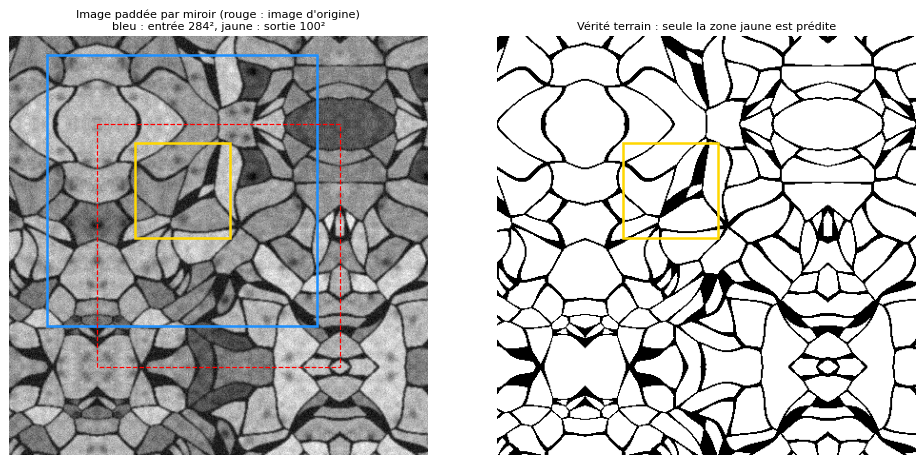

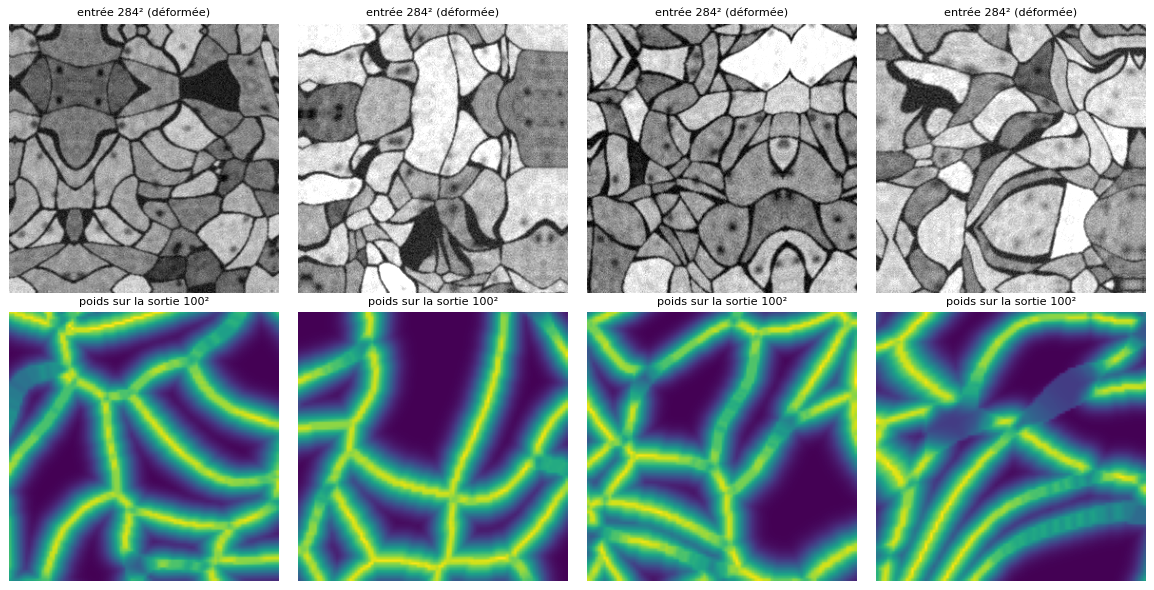

champ de déplacement : écart-type = [7.65 8.51] px | déplacement max = 33.2 px


In [17]:
PAD = (IN - OUT) // 2
train_imgs_p = [np.pad(a, PAD, mode="reflect") for a in train_imgs]
train_msks_p = [np.pad(a, PAD, mode="reflect") for a in train_msks]
train_wts_p  = [np.pad(a, PAD, mode="reflect") for a in train_wts]
print(f"tuile d'entrée {IN}x{IN} -> sortie {OUT}x{OUT} | marge miroir = {PAD}px | image paddée : {train_imgs_p[0].shape}")

# --- illustration de la Fig. 2 : zone prédite (jaune) et zone lue (bleu)
y0, x0 = 20, 40
fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
ax[0].imshow(train_imgs_p[0], vmin=0, vmax=1)
ax[0].add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), IN, IN, fill=False, ec="dodgerblue", lw=2))
ax[0].add_patch(plt.Rectangle((x0 + PAD - 0.5, y0 + PAD - 0.5), OUT, OUT, fill=False, ec="gold", lw=2))
ax[0].add_patch(plt.Rectangle((PAD - 0.5, PAD - 0.5), 256, 256, fill=False, ec="red", lw=1, ls="--"))
ax[0].set_title("Image paddée par miroir (rouge : image d'origine)\nbleu : entrée 284², jaune : sortie 100²", fontsize=9)
ax[1].imshow(train_msks_p[0], vmin=0, vmax=1)
ax[1].add_patch(plt.Rectangle((x0 + PAD - 0.5, y0 + PAD - 0.5), OUT, OUT, fill=False, ec="gold", lw=2))
ax[1].set_title("Vérité terrain : seule la zone jaune est prédite", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# --- exemple d'augmentation : même tuile, plusieurs tirages
rng_a = np.random.default_rng(11)
fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for j in range(4):
    xt, yt, wt = sample_tile(train_imgs_p, train_msks_p, train_wts_p, rng_a, augment=True)
    ax[0, j].imshow(xt[0, 0] + 0.5, vmin=0, vmax=1); ax[0, j].set_title("entrée 284² (déformée)", fontsize=9)
    ax[1, j].imshow(wt[0], cmap="viridis"); ax[1, j].set_title("poids sur la sortie 100²", fontsize=9)
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.show()

# --- champ de déplacement élastique
f = elastic_field((IN, IN), 10.0, 3, np.random.default_rng(3))
print("champ de déplacement : écart-type =", np.round(f.std(axis=(1, 2)), 2), "px | déplacement max =", round(float(np.abs(f).max()), 1), "px")

## 8. Entraînement

Comme dans le papier (§3) :
* **batch = 1 tuile** (on préfère de grandes tuiles à un grand batch) ;
* **SGD avec momentum 0,99** : v ← 0,99·v − lr·∇E ; θ ← θ + v ;
* énergie = softmax pixel à pixel + entropie croisée pondérée ;
* initialisation He, dropout à la fin du chemin contractant.

Le taux d'apprentissage n'est pas donné dans le papier ; avec un momentum aussi élevé (pas effectif lr / (1 − 0,99) = 100·lr) une valeur de **1e-3**, réduite de ×0,3 sur la fin de l'entraînement, est stable ici. Le nombre d'itérations est volontairement modeste (CPU, NumPy).

In [18]:
N_ITER, LR, MOMENTUM = 1200, 1e-3, 0.99
net = UNet(in_ch=1, n_classes=2, base=BASE, depth=DEPTH, p_drop=0.5, seed=SEED)
params = net.layers_with_params()
vel = [(np.zeros_like(l.W), np.zeros_like(l.b)) for l in params]
rng_train = np.random.default_rng(SEED)
hist = []; t0 = time.time()

for it in range(N_ITER):
    lr = LR if it < int(0.7 * N_ITER) else 0.3 * LR
    x, y, w = sample_tile(train_imgs_p, train_msks_p, train_wts_p, rng_train, augment=True)
    logits = net.forward(x, train=True)
    loss, dlogits = wce(logits, y, w)
    net.backward(dlogits)
    for l, (vw, vb) in zip(params, vel):
        vw *= MOMENTUM; vw -= lr * l.dW; l.W += vw
        vb *= MOMENTUM; vb -= lr * l.db; l.b += vb
    hist.append(loss)
    if it % 100 == 0 or it == N_ITER - 1:
        print(f"it {it:4d} | perte (moy. 50 dernières) = {np.mean(hist[-50:]):.4f} | {time.time() - t0:6.1f}s")
print(f"\nentraînement terminé en {time.time() - t0:.0f}s ({(time.time() - t0) / N_ITER:.2f}s / itération)")

it    0 | perte (moy. 50 dernières) = 3.5255 |    1.4s
it  100 | perte (moy. 50 dernières) = 2.1564 |  144.1s
it  200 | perte (moy. 50 dernières) = 1.4939 |  276.7s
it  300 | perte (moy. 50 dernières) = 1.3305 |  401.6s
it  400 | perte (moy. 50 dernières) = 1.0487 |  521.3s
it  500 | perte (moy. 50 dernières) = 0.9978 |  668.2s
it  600 | perte (moy. 50 dernières) = 0.9197 |  789.1s
it  700 | perte (moy. 50 dernières) = 0.8597 |  920.0s
it  800 | perte (moy. 50 dernières) = 0.7768 | 1060.2s
it  900 | perte (moy. 50 dernières) = 0.7875 | 1181.2s
it 1000 | perte (moy. 50 dernières) = 0.7705 | 1298.9s
it 1100 | perte (moy. 50 dernières) = 0.7864 | 1429.4s
it 1199 | perte (moy. 50 dernières) = 0.7585 | 1548.8s

entraînement terminé en 1549s (1.29s / itération)


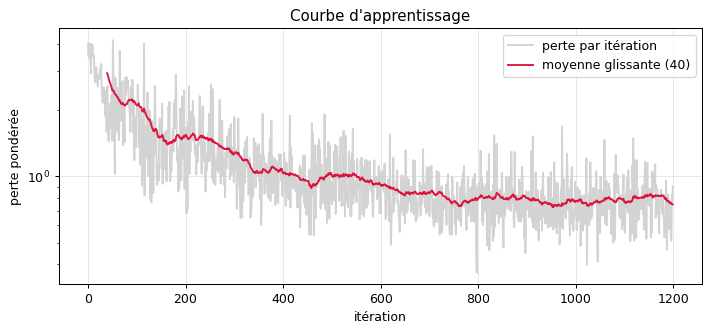

perte début (moy. 50 premières) : 2.728 -> fin (moy. 50 dernières) : 0.759


In [19]:
h = np.array(hist); k = 40
sm = np.convolve(h, np.ones(k) / k, mode="valid")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(h, color="lightgray", label="perte par itération")
ax.plot(np.arange(k - 1, len(h)), sm, color="crimson", label=f"moyenne glissante ({k})")
ax.set_xlabel("itération"); ax.set_ylabel("perte pondérée"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Courbe d'apprentissage"); plt.tight_layout(); plt.show()
print("perte début (moy. 50 premières) :", round(float(h[:50].mean()), 3), "-> fin (moy. 50 dernières) :", round(float(h[-50:].mean()), 3))

## 9. Inférence par tuiles et évaluation

**Inférence overlap-tile.** On pave l'image avec des fenêtres de sortie 100×100 (positions 0, 78, 156 pour une image 256 : la dernière fenêtre est recalée sur le bord et chevauche la précédente). Pour chacune, on lit l'entrée 284×284 dans l'image paddée par miroir. Le dropout est coupé. Comme dans le papier (« moyenne sur 7 versions pivotées »), on peut moyenner les probabilités sur **plusieurs rotations** de l'entrée (*test-time augmentation*, ici 4 rotations de 90°).

**Métriques** (inspirées du challenge ISBI 2012, version simplifiée) :
* **pixel error** = 1 − exactitude, après seuillage à 0,5 ;
* **Rand error** (simplifié) : 1 − F-score de Rand restreint aux pixels « cellule » de la vérité terrain, calculé entre les composantes connexes de la prédiction et les cellules vérité terrain ;
* **IoU** pour les classes cellule et membrane.

Le *warping error* du papier (Tableau 1) nécessite un recalage topologique et n'est pas reproduit ici.

In [20]:
def tile_positions(n, out=OUT):
    pos = list(range(0, max(n - out, 0) + 1, out))
    if pos[-1] != n - out: pos.append(n - out)
    return pos

def predict_prob(net, img, tta=False):
    # Probabilité 'cellule' pour chaque pixel, par stratégie overlap-tile (marges extrapolées par miroir).
    H, W = img.shape
    rots = [0, 1, 2, 3] if tta else [0]
    acc = np.zeros((H, W), np.float64)
    for k in rots:
        im = np.rot90(img, k)
        ip = np.pad(im, PAD, mode="reflect")
        pr = np.zeros((H, W), np.float64)
        for y in tile_positions(H):
            for x in tile_positions(W):
                tile = (ip[y:y + IN, x:x + IN] - 0.5)[None, None].astype(np.float32)
                z = net.forward(tile, train=False)
                z = z - z.max(1, keepdims=True); p = np.exp(z); p /= p.sum(1, keepdims=True)
                pr[y:y + OUT, x:x + OUT] = p[0, 1]
        acc += np.rot90(pr, -k)
    return acc / len(rots)

def rand_error(gt_lab, pred_lab):
    # 1 - F-score de Rand restreint au premier plan de la vérité terrain
    m = gt_lab > 0
    a, b = gt_lab[m].astype(np.int64), pred_lab[m].astype(np.int64)
    cont = np.zeros((a.max() + 1, b.max() + 1)); np.add.at(cont, (a, b), 1)
    sum_ij = (cont ** 2).sum(); sum_i = (cont.sum(1) ** 2).sum(); sum_j = (cont.sum(0) ** 2).sum()
    prec, rec = sum_ij / sum_j, sum_ij / sum_i
    return 1 - 2 * prec * rec / (prec + rec)

def evaluate(net, imgs, msks, tta=False, thr=0.5):
    rows, probs = [], []
    for img, m in zip(imgs, msks):
        p = predict_prob(net, img, tta); probs.append(p)
        pred = (p > thr).astype(np.uint8)
        pix_err = np.mean(pred != m)
        iou_c = np.logical_and(pred == 1, m == 1).sum() / np.logical_or(pred == 1, m == 1).sum()
        iou_m = np.logical_and(pred == 0, m == 0).sum() / np.logical_or(pred == 0, m == 0).sum()
        gl, _ = ndi.label(m); pl, _ = ndi.label(pred)
        rows.append((pix_err, rand_error(gl, pl), iou_c, iou_m))
    return np.array(rows), probs

t0 = time.time()
res, probs = evaluate(net, test_imgs, test_msks, tta=False)
print(f"évaluation sans TTA : {time.time() - t0:.1f}s")
base_err = np.mean([np.mean(m == 0) for m in test_msks])
print(f"\n{'image':<8}{'pixel error':>12}{'Rand error':>12}{'IoU cellule':>13}{'IoU membrane':>14}")
for i, r in enumerate(res): print(f"{i:<8}{r[0]:>12.4f}{r[1]:>12.4f}{r[2]:>13.4f}{r[3]:>14.4f}")
print(f"{'moyenne':<8}{res[:,0].mean():>12.4f}{res[:,1].mean():>12.4f}{res[:,2].mean():>13.4f}{res[:,3].mean():>14.4f}")
print(f"\nréférence triviale « tout = cellule » : pixel error = {base_err:.4f}")

évaluation sans TTA : 16.6s

image    pixel error  Rand error  IoU cellule  IoU membrane
0             0.0170      0.0420       0.9787        0.9236
1             0.0361      0.1609       0.9551        0.8439
2             0.0167      0.1346       0.9794        0.9179
3             0.0249      0.0737       0.9700        0.8715
4             0.0200      0.0445       0.9758        0.8980
moyenne       0.0229      0.0911       0.9718        0.8910

référence triviale « tout = cellule » : pixel error = 0.1877


In [21]:
t0 = time.time()
res_tta, probs_tta = evaluate(net, test_imgs, test_msks, tta=True)
print(f"évaluation avec TTA (4 rotations) : {time.time() - t0:.1f}s\n")
print(f"{'':<14}{'pixel error':>12}{'Rand error':>12}{'IoU cellule':>13}{'IoU membrane':>14}")
print(f"{'sans TTA':<14}" + "".join(f"{v:>{w}.4f}" for v, w in zip(res.mean(0), (12, 12, 13, 14))))
print(f"{'avec TTA':<14}" + "".join(f"{v:>{w}.4f}" for v, w in zip(res_tta.mean(0), (12, 12, 13, 14))))

évaluation avec TTA (4 rotations) : 58.0s

               pixel error  Rand error  IoU cellule  IoU membrane
sans TTA            0.0229      0.0911       0.9718        0.8910
avec TTA            0.0219      0.1011       0.9731        0.8957


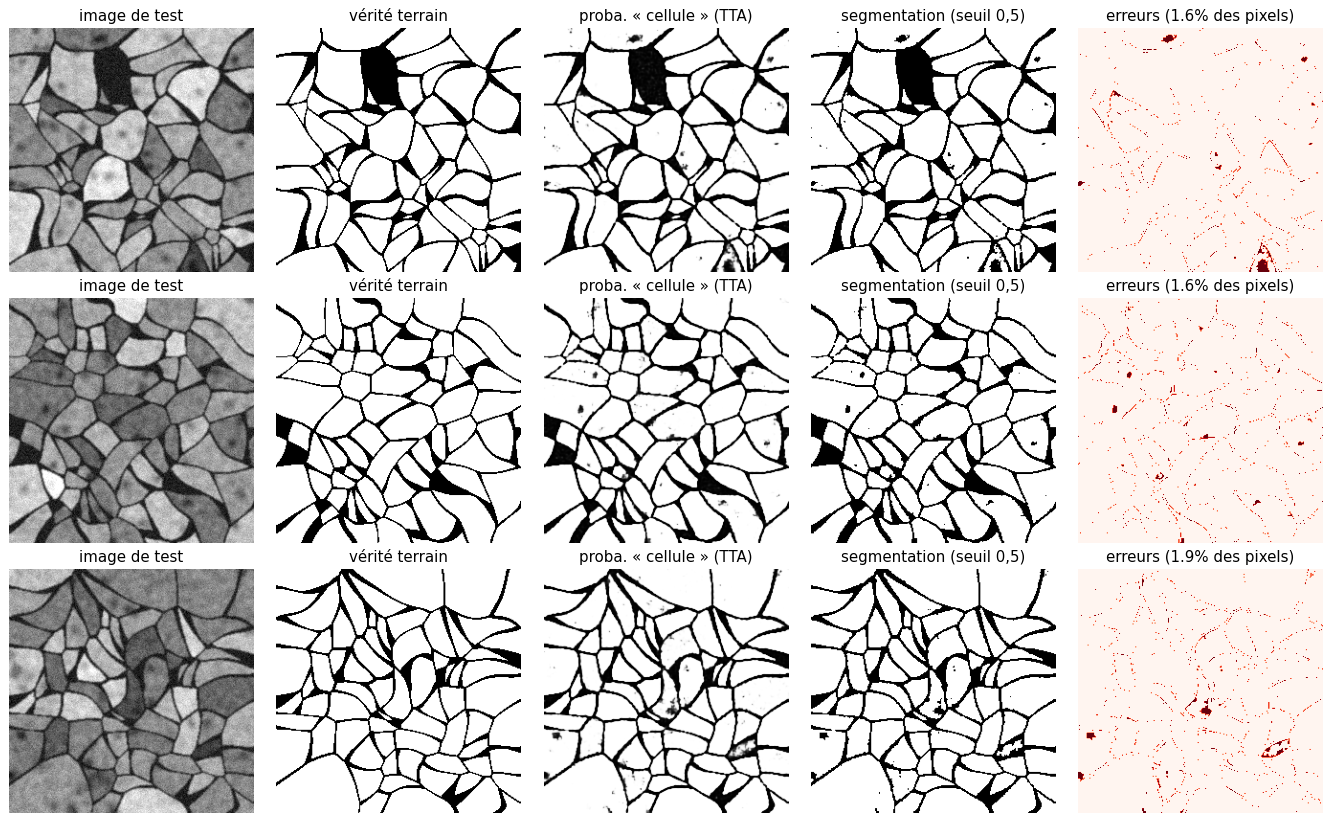

In [22]:
fig, ax = plt.subplots(3, 5, figsize=(15, 9.2))
for r_, i in enumerate((0, 2, 4)):
    p = probs_tta[i]; pred = (p > 0.5).astype(np.uint8)
    err = (pred != test_msks[i])
    ax[r_, 0].imshow(test_imgs[i], vmin=0, vmax=1); ax[r_, 0].set_title("image de test")
    ax[r_, 1].imshow(test_msks[i], vmin=0, vmax=1); ax[r_, 1].set_title("vérité terrain")
    ax[r_, 2].imshow(p, vmin=0, vmax=1);            ax[r_, 2].set_title("proba. « cellule » (TTA)")
    ax[r_, 3].imshow(pred, vmin=0, vmax=1);         ax[r_, 3].set_title("segmentation (seuil 0,5)")
    ax[r_, 4].imshow(err, cmap="Reds", vmin=0, vmax=1); ax[r_, 4].set_title(f"erreurs ({err.mean()*100:.1f}% des pixels)")
    for a in ax[r_]: a.axis("off")
plt.tight_layout(); plt.show()

### Effet de la perte pondérée sur les frontières

Les zones d'erreur se concentrent sur les **fines membranes** : c'est précisément ce que la carte de poids (Éq. 2) cherche à améliorer. On mesure l'exactitude **sur les pixels de frontière** (là où le poids de séparation est le plus élevé) par rapport au reste de l'image.

In [23]:
accs_border, accs_rest = [], []
for img, m, p in zip(test_imgs, test_msks, probs_tta):
    lab, n = instances_from_mask(m)
    _, d1, d2 = weight_map(m, lab, n, wc=wc)
    border = (d1 + d2) < 6.0                    # pixels proches de deux cellules à la fois
    pred = (p > 0.5).astype(np.uint8)
    accs_border.append(np.mean(pred[border] == m[border])); accs_rest.append(np.mean(pred[~border] == m[~border]))
print(f"exactitude sur les pixels de frontière entre cellules : {np.mean(accs_border):.3f}")
print(f"exactitude sur le reste de l'image                    : {np.mean(accs_rest):.3f}")

exactitude sur les pixels de frontière entre cellules : 0.964
exactitude sur le reste de l'image                    : 0.987


## 10. Bilan

### Correspondance papier ↔ notebook

| Papier | Notebook |
|---|---|
| Chemin contractant / expansif symétriques (Fig. 1) | `UNet.forward` : `enc`, `bott`, `up`, `dec` |
| Conv 3×3 non paddées, ReLU, max-pool 2×2, up-conv 2×2, conv 1×1 | `Conv`, `ReLU`, `MaxPool2`, `UpConv2` |
| Copy & crop | `center_crop` + `np.concatenate` |
| 23 couches convolutives, 31 M de paramètres | `unet_shapes`, `count_params(64, 4, 1, 2)` = 31 030 658 |
| Tuile 572 → 388 | `unet_shapes(572)` ; ici 284 → 100 |
| Overlap-tile et miroir (Fig. 2) | `np.pad(mode="reflect")`, `predict_prob` |
| Déformations élastiques 3×3, σ = 10 px, bicubique | `elastic_field` + `map_coordinates(order=3)` |
| Perte pondérée, w₀ = 10, σ ≈ 5 (Éq. 1–2, Fig. 3) | `weight_map`, `wce` |
| Init. He √(2/N) | `Conv.__init__` |
| SGD momentum 0,99, batch = 1 | boucle d'entraînement |
| Dropout en fin de chemin contractant | `UNet.forward` (`p_drop`) |
| Moyenne sur versions pivotées à l'inférence | `predict_prob(..., tta=True)` |

### Limites et passage à l'échelle
* Les chiffres obtenus (jeu **synthétique**, réseau à 8 canaux, ~1 200 itérations) illustrent que la méthode fonctionne et que le code est correct (gradients vérifiés) ; ils ne sont **pas** comparables au Tableau 1 (warping error 0,000353 sur ISBI 2012) ni au Tableau 2.
* Pour se rapprocher du papier : `USE_REAL_ISBI = True` avec les fichiers du challenge ISBI 2012, `BASE = 64`, tuile 572 → 388 (`IN, OUT = 572, 388`), beaucoup plus d'itérations. En NumPy c'est très lent (convolutions im2col de plusieurs Go de mémoire) : c'est précisément pour cela que les frameworks avec GPU sont utilisés en pratique.
* Les définitions de *Rand error* et *pixel error* sont simplifiées par rapport au serveur du challenge (qui seuille la carte de probabilité à 10 niveaux et calcule aussi le warping error).